# Masked-sky rotation reconstruction: with and without miscalibration
Single-frequency comparison at **nside=512**, **lmax_ivf=lmax_qlm=1024** using the existing isotropic filter.

Read **field 2 (zero-based, the third column)** of `binary_GAL_mask_N1024.fits`. Downgrade the mask from nside 1024 to 512 with `hp.ud_grade`; fractional edge weights are retained. The observation is
$$m_\nu^{\rm obs}=M\,[B_\nu\,R(\alpha_\nu)R(a(\hat n))m_{\rm CMB}+n_\nu].$$
The mask acts at the very last step, including on noise. Compare `alpha=None` with `alpha=0.2` **degrees**, retaining the same spatial rotation amplitude `Acb` and realization seeds. “Without alpha” here means no constant instrumental miscalibration, not removal of the anisotropic field.

**Interpretation:** the filter, full-sky QE response, and existing noise estimate are unchanged. Plotted reconstructed spectra are masked-sky diagnostics: no mean-field subtraction, mode-coupling correction, empirical response calibration, or sky-fraction rescaling is applied. The analytic full-sky input is a reference, not an exact prediction for the masked estimator.

In [1]:
%matplotlib inline
import hashlib
import json
from pathlib import Path
import sys
import time

import healpy as hp
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../src').resolve()))
from sim import CMBobs
from recon import AlphaRecon

plt.rcParams.update({'figure.dpi':120, 'axes.grid':True, 'grid.alpha':0.2})
nside = 512
lmax_ivf = 1024
lmax_qlm = 1024
lmin_ivf = 20
nlevp = 2.0       # uK-arcmin
fwhm = 8.0        # arcmin
Acb = 1e-7       # shared anisotropic rotation, rad²
alpha_deg = 0.05   # constant channel miscalibration, degrees
sim_indices = tuple(range(4))
bin_width = 32
mask_path = Path('../data/sky2.fits')
cinv = True
assert mask_path.exists(), f'Place the supplied mask at {mask_path.resolve()}'
assert len(sim_indices) >= 2

mask = hp.read_map(str(mask_path), dtype=float)
kwargs = dict(nside=nside, nlevp=nlevp, fwhm=fwhm, Acb=Acb, mask=mask)
obs_none = CMBobs(alpha=None, **kwargs)
obs_alpha = CMBobs(alpha=alpha_deg, **kwargs)
np.testing.assert_array_equal(obs_none.mask, mask)
np.testing.assert_array_equal(obs_alpha.mask, mask)
config = dict(nside=nside,lmax_ivf=lmax_ivf,lmax_qlm=lmax_qlm,lmin_ivf=lmin_ivf,
              nlevp=nlevp,fwhm=fwhm,Acb=Acb,alpha_deg=alpha_deg,
              mask_sha256=hashlib.sha256(mask.tobytes()).hexdigest())
tag = hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:16]
root = Path('libdir')/'masked_reconstruction'/tag
rec_kwargs = dict(lmin_ivf=lmin_ivf,lmax_ivf=lmax_ivf,lmax_qlm=lmax_qlm, cinv=cinv)
rec_none = AlphaRecon(obs_none,root/'no_alpha',**rec_kwargs)
rec_alpha = AlphaRecon(obs_alpha,root/'with_alpha',**rec_kwargs)
# Verify that only the simulated maps differ; the current filters are identical.
for name in ['get_ftl','get_fel','get_fbl']:
    np.testing.assert_array_equal(getattr(rec_none.ivfs,name)(),getattr(rec_alpha.ivfs,name)())
f1,f2,f4 = [np.mean(mask**power) for power in [1,2,4]]
print(f'Mask: mean(M)={f1:.6f}, mean(M²)={f2:.6f}, mean(M⁴)={f4:.6f}')
print(f'Fractional boundary pixels: {np.count_nonzero((mask>0)&(mask<1))}')
print('Both filters unchanged; no sky-fraction normalization applied.')
print('Cache:',root)

Using lenspyx alm2map
jit: instantiating ctype = <class 'plancklens.qcinv.multigrid.multigrid_chain'>
creating split preconditioner  ('dense(data/masked_reconstruction/15399d408e628835/no_alpha/freq_0_cinv/cinv_t/dense.pk)', '64', 'diag_cl')
creating dense preconditioner. (nside = 128, lmax = 64, cache = data/masked_reconstruction/15399d408e628835/no_alpha/freq_0_cinv/cinv_t/dense.pk)
jit: instantiating ctype = <class 'plancklens.qcinv.opfilt_tt.alm_filter_ninv'>
opfilt_tt: inverse noise map std dev / av = 1.656e-15
 [00:00:00] filling template (4) projection matrix -------> 75%
ninv_ftl: using 2.09 uK-amin noise Cl
DEGRADING WITH NO MARGE MAPS
opfilt_tt: inverse noise map std dev / av = 8.281e-02
 [00:00:00] filling template (4) projection matrix -------> 75%
ninv_ftl: using 2.09 uK-amin noise Cl
computing dense preconditioner:
     lmax  = 64
     ntmpl = 4
 will cache minv in data/masked_reconstruction/15399d408e628835/no_alpha/freq_0_cinv/cinv_t/dense.pk
 [00:00:13] filling matrix 

setting the output map dtype to [dtype('float64')]


ninv_ftl: using 2.09 uK-amin noise Cl
creating split preconditioner  ('stage(1)', '1024', 'diag_cl')
creating multigrid preconditioner: stage_id =  1
cinv_t::noiseT_uk_arcmin = 1.414
jit: instantiating ctype = <class 'plancklens.qcinv.multigrid.multigrid_chain'>
creating split preconditioner  ('dense(data/masked_reconstruction/15399d408e628835/no_alpha/freq_0_cinv/cinv_p/dense.pk)', '32', 'diag_cl')
creating dense preconditioner. (nside = 256, lmax = 32, cache = data/masked_reconstruction/15399d408e628835/no_alpha/freq_0_cinv/cinv_p/dense.pk)
jit: instantiating ctype = <class 'plancklens.qcinv.opfilt_pp.alm_filter_ninv'>
computing dense preconditioner:
     lmax  = 32
     ntmpl = 8
 [00:00:17] filling matrix ---------> 99%
   inverting M...
     eigv[ntmpl-1] =  7.999683652138164e-10
     eigv[ntmpl]   =  132.05197045564103


/Users/antoidicherianlonappan/Software/plancklens/plancklens/utils.py:124: RuntimeWarning: overflow encountered in cast
  return hashlib.sha1(np.copy(cl.astype(dtype), order='C')).hexdigest()
setting the output map dtype to [dtype('float64')]


ninv_febl: using 2.96 uK-amin noise Cl
creating split preconditioner  ('stage(2)', '512', 'diag_cl')
creating multigrid preconditioner: stage_id =  2
creating split preconditioner  ('stage(1)', '1024', 'diag_cl')
creating multigrid preconditioner: stage_id =  1
cinv_p::noiseP_uk_arcmin = 2.000


...

ninv_ftl: using 2.09 uK-amin noise Cl
creating split preconditioner  ('stage(1)', '1024', 'diag_cl')
creating multigrid preconditioner: stage_id =  1
cinv_t::noiseT_uk_arcmin = 1.414
jit: instantiating ctype = <class 'plancklens.qcinv.multigrid.multigrid_chain'>
creating split preconditioner  ('dense(data/masked_reconstruction/15399d408e628835/with_alpha/freq_0_cinv/cinv_p/dense.pk)', '32', 'diag_cl')
creating dense preconditioner. (nside = 256, lmax = 32, cache = data/masked_reconstruction/15399d408e628835/with_alpha/freq_0_cinv/cinv_p/dense.pk)
jit: instantiating ctype = <class 'plancklens.qcinv.opfilt_pp.alm_filter_ninv'>
computing dense preconditioner:
     lmax  = 32
     ntmpl = 8
 [00:00:17] filling matrix ---------> 99%
   inverting M...
     eigv[ntmpl-1] =  7.999683652138164e-10
     eigv[ntmpl]   =  132.05197045564103


setting the output map dtype to [dtype('float64')]


ninv_febl: using 2.96 uK-amin noise Cl
creating split preconditioner  ('stage(2)', '512', 'diag_cl')
creating multigrid preconditioner: stage_id =  2
creating split preconditioner  ('stage(1)', '1024', 'diag_cl')
creating multigrid preconditioner: stage_id =  1
cinv_p::noiseP_uk_arcmin = 2.000


setting the output map dtype to [dtype('>f8')]


Caching sky fractions...
Mask: mean(M)=0.456888, mean(M²)=0.456888, mean(M⁴)=0.456888
Fractional boundary pixels: 0
Both filters unchanged; no sky-fraction normalization applied.
Cache: data/masked_reconstruction/15399d408e628835


## Matched reconstruction ensemble
Each pair uses identical CMB, spatial rotation, and noise seeds. Only the constant miscalibration differs. The truth alms below describe the common full-sky anisotropic field; cross-spectra measure how the masked reconstruction responds to it.

The existing `AlphaRecon.noise_spectrum` is a full-sky semi-analytical estimate applied to masked data. Its subtraction is displayed as a diagnostic only; it is not a calibrated cut-sky bias subtraction.

In [2]:
L=np.arange(lmax_qlm+1)
cl_aa=obs_none.cl_aa()[:lmax_qlm+1]
ells,ms=hp.Alm.getlm(lmax_qlm)
selection=hp.Alm.getidx(obs_none.lmax,ells,ms)
results={case:{key:[] for key in ['auto','cross','n0']} for case in ['no_alpha','with_alpha']}
input_cls=[]
start=time.perf_counter()
for idx in sim_indices:
    truth=obs_none.alpha_alm(idx)[selection]
    input_cls.append(hp.alm2cl(truth))
    for case,rec in [('no_alpha',rec_none),('with_alpha',rec_alpha)]:
        estimate=rec.reconstruct(idx)
        results[case]['auto'].append(hp.alm2cl(estimate))
        results[case]['cross'].append(hp.alm2cl(estimate,truth))
        results[case]['n0'].append(rec.noise_spectrum(idx))
        print(f'{case}, idx={idx}, elapsed={time.perf_counter()-start:.1f} s',flush=True)
results={case:{key:np.asarray(value) for key,value in values.items()}
         for case,values in results.items()}
input_cls=np.asarray(input_cls)
assert all(np.isfinite(value).all() for values in results.values() for value in values.values())
np.savez(root/'comparison_cls.npz',ell=L,theory=cl_aa,input=input_cls,
         indices=np.array(sim_indices),**{f'{case}_{key}':value
             for case,values in results.items() for key,value in values.items()})
print('Saved raw spectra:',root/'comparison_cls.npz')

( 512, 1024) [00:00:02] (0, 1.00000000)
( 512, 1024) [00:00:05] (1, 0.01238026)
( 512, 1024) [00:00:08] (2, 0.00740576)
( 512, 1024) [00:00:11] (3, 0.00536155)
( 512, 1024) [00:00:13] (4, 0.00407257)
( 512, 1024) [00:00:16] (5, 0.00316719)
( 512, 1024) [00:00:19] (6, 0.00227320)
( 512, 1024) [00:00:21] (7, 0.00177505)
( 512, 1024) [00:00:24] (8, 0.00128075)
( 512, 1024) [00:00:27] (9, 0.00100945)
( 512, 1024) [00:00:30] (10, 0.00075637)
( 512, 1024) [00:00:32] (11, 0.00059927)
( 512, 1024) [00:00:36] (12, 0.00047375)
( 512, 1024) [00:00:38] (13, 0.00037230)
( 512, 1024) [00:00:42] (14, 0.00031529)
( 512, 1024) [00:00:45] (15, 0.00025717)
( 512, 1024) [00:00:48] (16, 0.00022505)
( 512, 1024) [00:00:51] (17, 0.00019433)
( 512, 1024) [00:00:54] (18, 0.00016946)
( 512, 1024) [00:00:58] (19, 0.00014637)
( 512, 1024) [00:01:01] (20, 0.00012385)
( 512, 1024) [00:01:05] (21, 0.00010409)
( 512, 1024) [00:01:08] (22, 0.00008717)
( 512, 1024) [00:01:12] (23, 0.00007335)
( 512, 1024) [00:01:15] (2

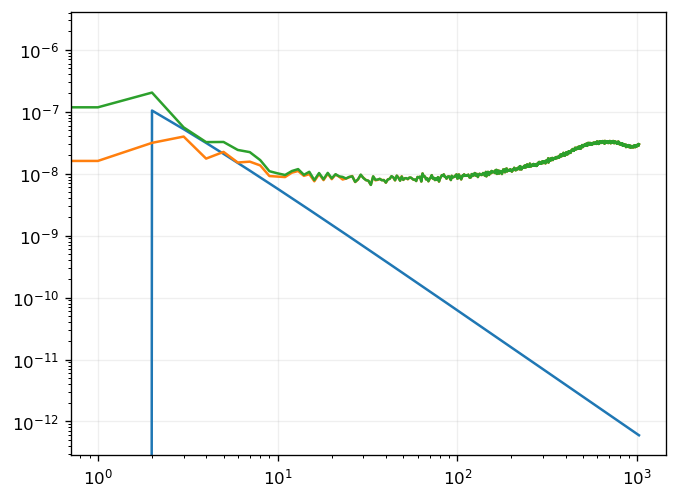

In [3]:
plt.loglog(cl_aa)
plt.loglog(results['no_alpha']['auto'].mean(axis=0), label='No alpha')
plt.loglog(results['with_alpha']['auto'].mean(axis=0), label='With alpha')
plt.show()

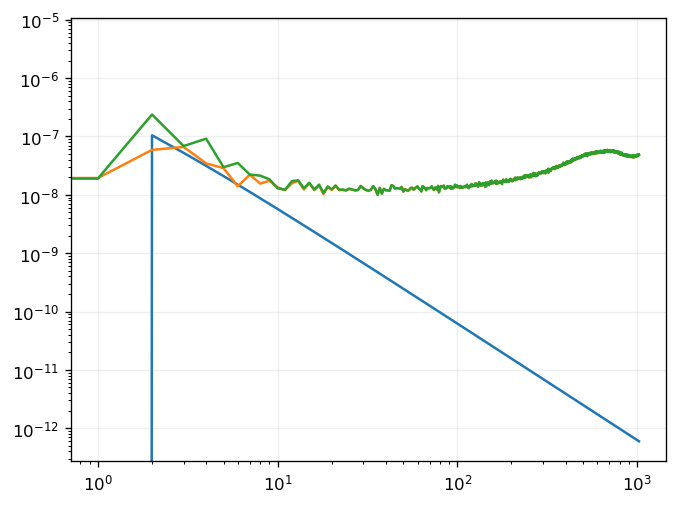

In [20]:
plt.loglog(cl_aa)
plt.loglog(results['no_alpha']['auto'].mean(axis=0), label='No alpha')
plt.loglog(results['with_alpha']['auto'].mean(axis=0), label='With alpha')
plt.show()
